# Checks for simulation and configuration files



In [12]:
import rebound as rb
import pandas as pd
import numpy as np
from datetime import datetime
import time

import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline


In [15]:
family = rb.Simulation(f'../../asteroid_data/sim_data/mvc_3/inputs/family_sim.bin')
print(f'Number of particles in simulation:{len(family.particles)}, Number active:{family.N_active} Number of test particles {len(family.particles)-family.N_active}')

path = '../../asteroid_data/sim_data/mvc_3/inputs/family_assignments.h5'
family_particles = pd.read_hdf(path)
family_particles.head()

Number of particles in simulation:887, Number active:9 Number of test particles 878


,ast_name,particle_number
0,1303,10
1,11911,11
2,16794,12
3,17840,13
4,26558,14


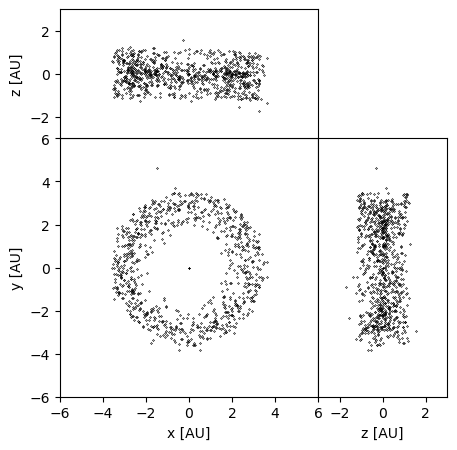

In [16]:
parts = range(9, 887)
rb.OrbitPlotSet(family, unitlabel="[AU]", particles = parts, orbit_style=None, periastron=True, xlim=[-6,6], ylim=[-6,6], lw=0.001)

In [17]:
max_a = 0
max_e = 0
max_inc = 0
min_a = 0
min_e = 0
min_inc = 0

orbital_parameters = np.zeros([len(family.particles)-9, 11])

for i_p, part in enumerate(family.particles[9:]):
    orbital_parameters[i_p][0] = part.x
    orbital_parameters[i_p][1] = part.y
    orbital_parameters[i_p][2] = part.z
    orbital_parameters[i_p][3] = part.vx
    orbital_parameters[i_p][4] = part.vy
    orbital_parameters[i_p][5] = part.vz
    orbital_parameters[i_p][6] = part.a
    orbital_parameters[i_p][7] = part.e
    orbital_parameters[i_p][8] = part.inc
    orbital_parameters[i_p][9] = part.omega
    orbital_parameters[i_p][10] = part.Omega

orb_params_cols = ['x', 'y', 'z','vx', 'vy', 'vz', 'a', 'e', 'inc', 'omega', 'Omega']
orb_params_df = pd.DataFrame(orbital_parameters, columns=orb_params_cols)

orb_params_df['inc_deg'] = np.degrees(np.arcsin(orb_params_df['inc']))
    

In [18]:
orb_params_df.describe()

,x,y,z,vx,vy,vz,a,e,inc,omega,Omega,inc_deg
count,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000
mean,-0.147368,0.075935,-0.026908,-0.020487,0.000004,-0.002366,2.947124,0.136590,0.237138,3.169470,0.112541,13.814335
std,2.113801,2.071234,0.584213,0.405425,0.411884,0.104541,0.346743,0.056207,0.116878,1.807985,1.818529,6.899008
min,-3.587538,-3.827160,-1.708043,-0.756026,-0.722574,-0.291733,1.819897,0.000715,0.006864,0.002055,-3.138470,0.393282
25%,-2.189848,-1.888574,-0.431272,-0.394870,-0.402887,-0.079120,2.674494,0.099846,0.128718,1.613897,-1.418201,7.395519
50%,-0.204625,0.203713,-0.009700,-0.044725,-0.014269,-0.002883,3.150842,0.128467,0.288379,3.134421,0.264111,16.760943
75%,1.840068,1.981174,0.379906,0.384056,0.404108,0.067986,3.204949,0.165325,0.331044,4.711815,1.638020,19.332142
max,3.638120,4.622391,1.555470,0.743182,0.818673,0.338004,3.944617,0.330849,0.545651,6.278274,3.136667,33.069177


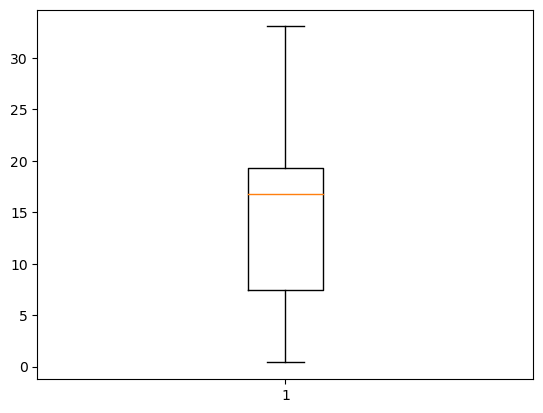

In [21]:
plt.boxplot(orb_params_df.inc_deg)
plt.show()

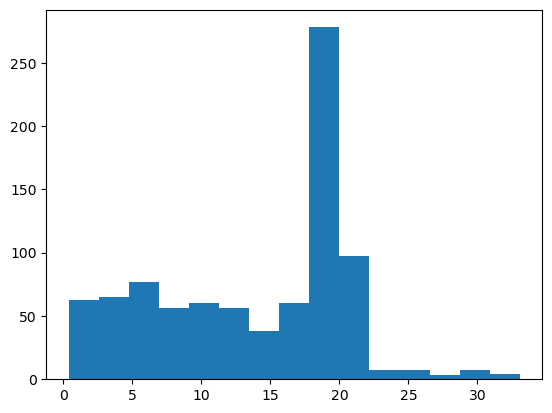

In [85]:
plt.hist(orb_params_df.inc_deg, bins=15)
plt.show()


In [20]:

orb_params_df[(orb_params_df.a <= 2.1) | (orb_params_df.a >= 3.9)].sort_values('a')

orb_params_df[(orb_params_df.e >= 0.3)].sort_values('e')

orb_params_df[(orb_params_df.inc >= 0.5)].sort_values('inc_deg')

,x,y,z,vx,vy,vz,a,e,inc,omega,Omega,inc_deg
567,-2.715954,1.108117,1.255276,-0.124797,-0.440539,-0.180780,2.598539,0.326027,0.504749,4.749746,0.498647,30.314714
850,2.602703,0.341141,-0.641064,0.131273,0.555110,0.218649,2.721271,0.236888,0.509564,3.994290,0.582646,30.634810
866,1.469854,0.655471,0.859202,-0.298805,0.777086,-0.119534,2.565562,0.289611,0.511113,1.938892,-1.462597,30.738005
534,2.008551,1.577490,-0.012219,-0.318776,0.497689,0.338004,3.123551,0.198940,0.521853,5.773752,0.674087,31.456656
779,0.518130,2.286174,0.240136,-0.581996,0.093511,0.330296,2.545843,0.074593,0.523452,0.281828,1.169487,31.564062
608,2.076007,-0.133270,0.904629,-0.183898,0.657313,0.166710,2.573046,0.231085,0.539260,2.135454,-0.877575,32.633287
713,-1.652708,-1.992777,0.567857,0.490425,-0.236871,0.270639,2.596026,0.116530,0.545651,2.291055,-2.632807,33.069177


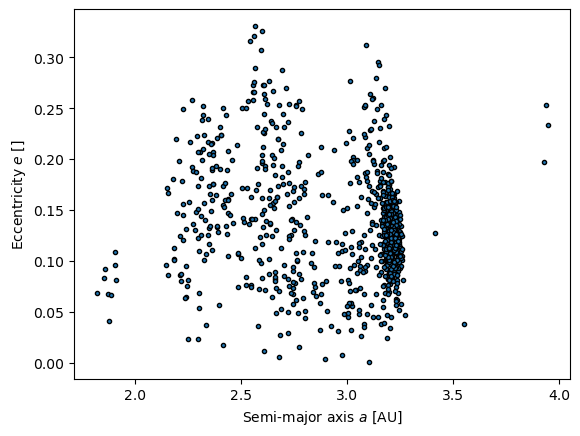

In [22]:
plt.scatter(data=orb_params_df, x='a',y='e', edgecolors='black', marker=".")
plt.xlabel("Semi-major axis $a$ [AU]")
plt.ylabel("Eccentricity $e$ []")
plt.show()

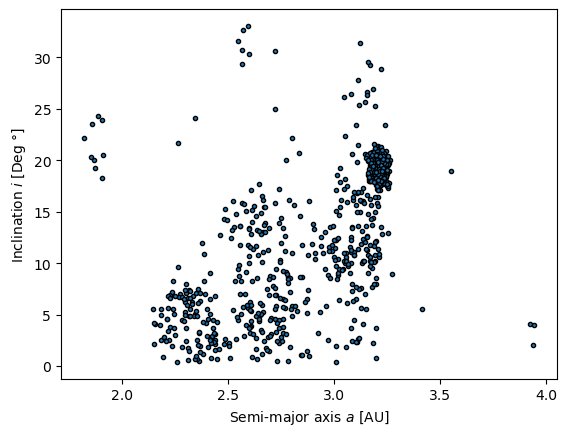

In [23]:
plt.scatter(data=orb_params_df, x='a',y='inc_deg', edgecolors='black', marker=".")
plt.xlabel("Semi-major axis $a$ [AU]")
plt.ylabel("Inclination $i$ [Deg $\degree$]")
plt.show()

In [2]:
complete_1step = rb.Simulation(f'../../asteroid_data/sim_data/mvc_3/check_files/sim_actives_fin.bin')


In [3]:
complete_2step = rb.Simulation(f'../../asteroid_data/sim_data/mvc_3/results/sim_actives_fin.bin')


In [5]:
complete_1step.status()

---------------------------------
REBOUND version:     	3.22.0
REBOUND built on:    	Nov 22 2022 18:31:19
Number of particles: 	9
Selected integrator: 	mercurius
Simulation time:     	6.2197300860093709e+05
Current timestep:    	0.128843
---------------------------------
<rebound.particle.Particle object at 0x139b499a0, m=0.9999999999950272 x=0.0053899889960199905 y=0.0011109756597511469 z=-0.00019365303515049657 vx=0.00011010178112383927 vy=0.0004178991946358054 vz=-2.5384935360239403e-06>
<rebound.particle.Particle object at 0x139b49ac0, m=2.447838287784771e-06 x=-0.31978052121024114 y=-0.661419358284709 z=0.006235007285944991 vx=1.0311772596112057 vy=-0.5136329931922691 vz=0.0017557930657317285>
<rebound.particle.Particle object at 0x139b499a0, m=3.0404326489511185e-06 x=-0.6563028225608195 y=-0.7552041632763806 z=0.06049956422163843 vx=0.7406389116545106 vy=-0.6613810338493832 vz=-0.015344397467639612>
<rebound.particle.Particle object at 0x139b49ac0, m=3.2271560828978514e-07 x=-1.

In [7]:
complete_2step.status()

---------------------------------
REBOUND version:     	3.22.0
REBOUND built on:    	Nov 22 2022 18:31:19
Number of particles: 	9
Selected integrator: 	mercurius
Simulation time:     	6.2197300860093709e+05
Current timestep:    	0.128843
---------------------------------
<rebound.particle.Particle object at 0x139b499a0, m=0.9999999999950272 x=0.0053899889960199905 y=0.0011109756597511469 z=-0.00019365303515049657 vx=0.00011010178112383927 vy=0.0004178991946358054 vz=-2.5384935360239403e-06>
<rebound.particle.Particle object at 0x139b49ac0, m=2.447838287784771e-06 x=-0.31978052121024114 y=-0.661419358284709 z=0.006235007285944991 vx=1.0311772596112057 vy=-0.5136329931922691 vz=0.0017557930657317285>
<rebound.particle.Particle object at 0x139b499a0, m=3.0404326489511185e-06 x=-0.6563028225608195 y=-0.7552041632763806 z=0.06049956422163843 vx=0.7406389116545106 vy=-0.6613810338493832 vz=-0.015344397467639612>
<rebound.particle.Particle object at 0x139b49ac0, m=3.2271560828978514e-07 x=-1.

,x,y,z,vx,vy,vz,a,e,inc,omega,Omega,inc_deg


,x,y,z,vx,vy,vz,a,e,inc,omega,...,Z,VX,VY,VZ,sX,sY,sZ,sVX,sVY,sVZ
0,3.359408,-0.452480,-1.186056,0.076525,0.487677,0.026783,3.196581,0.123494,0.341412,1.754517,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2.140391,1.429843,-0.830626,-0.361320,0.530306,-0.111506,3.166572,0.152200,0.352546,3.900340,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.840324,-3.311674,0.736326,0.464880,0.160835,-0.142257,3.221986,0.161408,0.333995,4.699687,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2.750743,-0.702947,0.541571,0.211363,0.560981,-0.148605,3.215270,0.117225,0.319639,1.908554,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,-2.853475,1.822653,0.823708,-0.324942,-0.380450,-0.104601,3.194652,0.122694,0.332438,6.131821,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
874,-2.266081,1.415571,0.017248,-0.338676,-0.511429,-0.015646,2.684427,0.026777,0.026481,1.472692,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
875,2.549643,-0.845969,0.011387,0.141149,0.559646,-0.032054,2.434288,0.126676,0.055479,5.662392,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
876,-2.300895,0.371392,-0.221078,-0.149968,-0.679877,-0.056108,2.724287,0.154334,0.120524,3.551780,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
877,-2.694938,0.660010,0.156196,-0.148810,-0.571451,0.063353,2.721475,0.029408,0.119866,4.379886,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
